# Sentinel-3/OLCI matchups with RadCalNet-OC

This tutorial compares the top-of-atmosphere (TOA) radiance measured by the Ocean and Land Colour
Instrument (OLCI) of Sentinel-3A and Sentinel-3B with the RadCalNet-OC simulations computed from the
measurements of the AERONET-OC station *Galata_Platform* (Black Sea, 43.04° N, 28.19° E). The ratio of
the measured to the simulated radiance, band by band, is the quantity used for the vicarious
calibration and the radiometric validation of the sensor.

The steps are:

1. extraction of the OLCI pixels around the station from yearly datacubes of Level-1B images;
2. screening of the scenes: quality, cloud and sunglint flags, viewing geometry and spatial uniformity;
3. computation of the simulated radiance in the OLCI bands, at the geometry of each scene and within
   $\pm 1$ h of the overpass;
4. comparison: spectra, time series, scatter plots and ratio per band for each platform.

The simulated TOA radiance is computed from the TOA reflectance $R_{toa}$ and the plane solar irradiance
at TOA $E_0$ of the RadCalNet-OC output (Eq. {eq}`e0`),

$$
L_{toa}(\lambda) = \frac{E_0(\lambda)\, R_{toa}(\lambda)}{\pi},
$$

and integrated over the spectral response $S_b$ of each OLCI band $b$ (Eq. {eq}`convolution`),

$$
L_{toa}^{b} = \frac{\int L_{toa}(\lambda)\, S_b(\lambda)\, d\lambda}{\int S_b(\lambda)\, d\lambda},
$$

with $S_b$ modelled by super-Gaussian functions centred on the characterised central wavelength of the
band, with its full width at half maximum ({py:class}`~radcalnet_oc.lut.Spectral`).

```{note}
The input data are not distributed with the package: the OLCI datacubes (radiance, flags and geometry
of the Level-1B images around the station, with OmniCloudMask cloud flags and sunglint flags) and the
RadCalNet-OC simulations of the station (computed with the {doc}`../processing_chain`) are read from
local directories, set in the *Parameters* section.
```

In [1]:
import glob
import logging
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18})
# no warning when the Times New Roman font is not installed
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import scipy.stats
import xarray as xr

import radcalnet_oc as radoc
# radcalnet_oc sets the root logger to INFO: show only the warnings in this tutorial
logging.getLogger().setLevel(logging.WARNING)
print(f'radcalnet_oc: {radoc.__version__}')

radcalnet_oc: 0.0.3


## Parameters

The matchup criteria follow the usual practice of the radiometric validation of ocean colour sensors:
a box of $3\times3$ pixels centred on the station, free of any flag, in a neighbourhood of
$15\times15$ pixels (about $4\times4$ km$^2$) with less than 5 % of cloudy pixels, and a spatially uniform
signal (coefficient of variation in the box below 5 % at 865 nm). The viewing zenith angle must be
covered by the simulations (0 to 40°).

In [2]:
# AERONET-OC station
site = 'Galata_Platform'
site_lat, site_lon = 43.044624, 28.19319

# OLCI datacubes (one NetCDF file per year) and RadCalNet-OC simulations (one file per month)
olci_files = sorted(glob.glob('/data/radcalnet/sentinel3/datacube/Galata/s3_dc_Galata_*.nc'))
radcalnet_files = sorted(glob.glob(f'/data/radcalnet/data_v0.0.2/full_spectral/{site}/{site}_radcalnet-oc_lev20_*.nc'))
# directory of the matchup file written at the end of the tutorial
odir = '/data/radcalnet/sentinel3/matchup'

# matchup criteria
half_box = 1                         # box of 3x3 pixels centred on the station
half_neighbourhood = 7               # neighbourhood of 15x15 pixels for the cloud cover
max_cloud_fraction = 0.05            # in the neighbourhood
max_cv = 0.05                        # coefficient of variation in the box at cv_wl
cv_wl = 865
max_vza, max_sza = 40, 70            # deg; 40 deg is the largest viewing angle of the simulations
max_distance = 300                   # maximum distance between the station and the nearest pixel (m)
delta_time = np.timedelta64(1, 'h')  # time window of the simulations around the overpass

print(f'{len(olci_files)} OLCI datacubes, {len(radcalnet_files)} RadCalNet-OC files')

8 OLCI datacubes, 73 RadCalNet-OC files


## Extraction of the OLCI pixels around the station

The datacubes contain, for each overpass, a subset of the Level-1B image in the satellite geometry
(dimensions `y`, `x`), with the latitude and longitude of each pixel. The position of the station in the
subset changes from one overpass to the other, by several pixels: the pixel nearest to the station is
searched in each scene, and the $15\times15$ pixels around it are extracted (dimensions `dy`, `dx`).

The compressed files are chunked along time: a block of consecutive scenes is read at once, which is
much faster than reading the scenes one by one.

In [3]:
def extract_site(file):
    """Pixels of the neighbourhood of the station for each scene of an OLCI datacube."""
    dc = xr.open_dataset(file)
    nt, ny, nx = dc.sizes['time'], dc.sizes['y'], dc.sizes['x']

    # nearest pixel of the station in each scene
    lat, lon = dc.latitude.values, dc.longitude.values
    d2 = ((lat - site_lat) ** 2 + ((lon - site_lon) * np.cos(np.radians(site_lat))) ** 2).reshape(nt, -1)
    nearest = np.nanargmin(d2, axis=1)
    distance = np.sqrt(d2[np.arange(nt), nearest]) * 111.2e3
    iy, ix = np.unravel_index(nearest, (ny, nx))

    h = half_neighbourhood
    ok = (distance < max_distance) & (iy >= h) & (iy < ny - h) & (ix >= h) & (ix < nx - h)
    if not ok.any():
        return None
    y0, y1 = iy[ok].min() - h, iy[ok].max() + h + 1
    x0, x1 = ix[ok].min() - h, ix[ok].max() + h + 1

    # read the window containing all the neighbourhoods, then pick the neighbourhood of each scene
    variables = ['radiance', 'flags', 'SZA', 'OZA', 'SAA', 'OAA', 'central_wl', 'FWHM_mean', 'platform']
    window = dc[variables].isel(y=slice(y0, y1), x=slice(x0, x1)).load().isel(time=np.flatnonzero(ok))
    offset = xr.DataArray(np.arange(-h, h + 1), dims='dy'), xr.DataArray(np.arange(-h, h + 1), dims='dx')
    yy = xr.DataArray(iy[ok] - y0, dims='time') + offset[0]
    xx = xr.DataArray(ix[ok] - x0, dims='time') + offset[1]
    neighbourhood = window.isel(y=yy, x=xx).drop_vars(['latitude', 'longitude', 'altitude', 'time_stamp'])

    # position of the station in the scene, for the figures
    neighbourhood['iy'] = ('time', iy[ok])
    neighbourhood['ix'] = ('time', ix[ok])
    neighbourhood['distance'] = ('time', distance[ok])
    neighbourhood['file'] = ('time', [os.path.basename(file)] * ok.sum())
    return neighbourhood


olci = xr.concat([extract_site(file) for file in olci_files], dim='time')
olci

<xarray.Dataset> Size: 75MB
Dimensions:     (time: 2736, wl: 21, dy: 15, dx: 15)
Coordinates:
  * time        (time) datetime64[ns] 22kB 2017-01-01T08:19:38.725373888 ... ...
  * wl          (wl) int64 168B 400 412 443 491 511 560 ... 865 884 899 939 1016
    y           (time, dy) int64 328kB 73 74 75 76 77 78 ... 85 86 87 88 89 90
    x           (time, dx) int64 328kB 80 81 82 83 84 85 ... 93 94 95 96 97 98
Dimensions without coordinates: dy, dx
Data variables: (12/13)
    radiance    (time, wl, dy, dx) float32 52MB 51.55 50.75 ... 1.283 1.463
    flags       (time, dy, dx) uint32 2MB 8192 8192 8192 8192 ... 0 0 8388608 0
    SZA         (time, dy, dx) float64 5MB 70.85 70.85 70.85 ... 68.52 68.52
    OZA         (time, dy, dx) float64 5MB 30.04 30.02 30.01 ... 17.46 17.48
    SAA         (time, dy, dx) float64 5MB 152.9 152.9 152.9 ... 160.5 160.5
    OAA         (time, dy, dx) float64 5MB 101.3 101.3 101.3 ... -73.43 -73.42
    ...          ...
    FWHM_mean   (time, wl) float32 230kB 14.0 9.839 9.956 ... 9.955 19.85 27.13
    platform    (time) <U3 33kB 'S3A' 'S3A' 'S3A' 'S3A' ... 'S3A' 'S3A' 'S3B'
    iy          (time) int64 22kB 80 83 80 82 79 82 79 ... 79 80 77 81 83 80 83
    ix          (time) int64 22kB 87 91 86 90 87 88 85 ... 86 87 81 88 91 86 91
    distance    (time) float64 22kB 181.4 158.5 132.1 ... 86.99 180.8 149.2
    file        (time) <U20 219kB 's3_dc_Galata_2017.nc' ... 's3_dc_Galata_20...
Attributes: (12/19)
    absolute_orbit_number:  4557
    ac_subsampling_factor:  64
    al_subsampling_factor:  1
    comment:                 
    contact:                ops@eumetsat.int
    creation_time:          2026-03-17T14:12:44.257857+00:00
    ...                     ...
    source:                 IPF-OL-1-EO 06.19
    start_time:             2017-01-01T08:16:52.705224Z
    stop_time:              2017-01-01T08:19:52.670260Z
    title:                  OLCI Level 1b Product, Radiometric Uncertainty Es...
    processed_by:           OLCI Datacube Generator
    original_product:       S3A_OL_1_EFR____20170101T081653_20170101T081953_2...

## Flags

The `flags` variable gathers, bit by bit:

- the classification and quality flags of the OLCI Level-1B product, at the bits given by the
  `flag_masks` and `flag_meanings` attributes (bits 19 to 31);
- the thick cloud, thin cloud and cloud shadow masks of OmniCloudMask and three levels of sunglint
  reflectance (> 0.04, > 0.1, > 0.2), at the bits 13 to 18 of the `flag_names` attribute.

```{warning}
In these datacubes, the bits 0 to 12 of the `flag_names` attribute repeat the names of the OLCI flags,
but these bits are never raised: the OLCI flags are decoded from `flag_masks` and `flag_meanings`.
```

In [4]:
attrs = olci.flags.attrs
flag_bits = {name: int(np.log2(mask)) for mask, name in zip(attrs['flag_masks'], attrs['flag_meanings'].split())}
flag_bits.update({name: bit for bit, name in enumerate(attrs['flag_names']) if 13 <= bit <= 18})


def flag_mask(names):
    return np.uint32(sum(1 << flag_bits[name] for name in names))


# proportion of the scenes with the flag raised in the box of 3x3 pixels
center = slice(half_neighbourhood - half_box, half_neighbourhood + half_box + 1)
box_flags = olci.flags.isel(dy=center, dx=center)
pd.DataFrame({'bit': flag_bits,
              'scenes (%)': {name: 100 * float(((box_flags & flag_mask([name])) != 0).any(['dy', 'dx']).mean())
                             for name in flag_bits}}).sort_values('bit').round(1).T

,OCM_thick_cloud,OCM_thin_cloud,OCM_cloud_shadow,sunglint_moderate,sunglint_high,sunglint_extreme,partially_saturated,saturated,dubious,sun-glint_risk,duplicated,cosmetic,invalid,straylight_risk,bright,tidal_region,fresh_inland_water,coastline,land
bit,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,29.0,30.0,31.0
scenes (%),50.1,1.4,4.0,5.2,1.8,0.0,0.2,0.2,0.3,21.5,49.7,0.0,0.1,0.1,38.9,0.0,0.0,0.0,0.0


The `duplicated` flag marks the pixels duplicated by the regridding of the image and the `sun-glint_risk`
flag of the Level-1B product covers a large part of the scenes: they are not used. The sunglint is
screened with the sunglint flags of the datacube and the clouds with the OmniCloudMask flags and the
`bright` flag.

In [5]:
bad_flags = ['invalid', 'saturated', 'partially_saturated', 'dubious', 'cosmetic', 'straylight_risk',
             'land', 'coastline', 'bright',
             'OCM_thick_cloud', 'OCM_thin_cloud', 'OCM_cloud_shadow',
             'sunglint_moderate', 'sunglint_high', 'sunglint_extreme']
cloud_flags = ['bright', 'OCM_thick_cloud', 'OCM_thin_cloud', 'OCM_cloud_shadow']
glint_flags = ['sunglint_moderate', 'sunglint_high', 'sunglint_extreme']

### Quick look

True-colour composites of consecutive overpasses, with the cloud (red) and sunglint (orange) flags and the
box around the station.

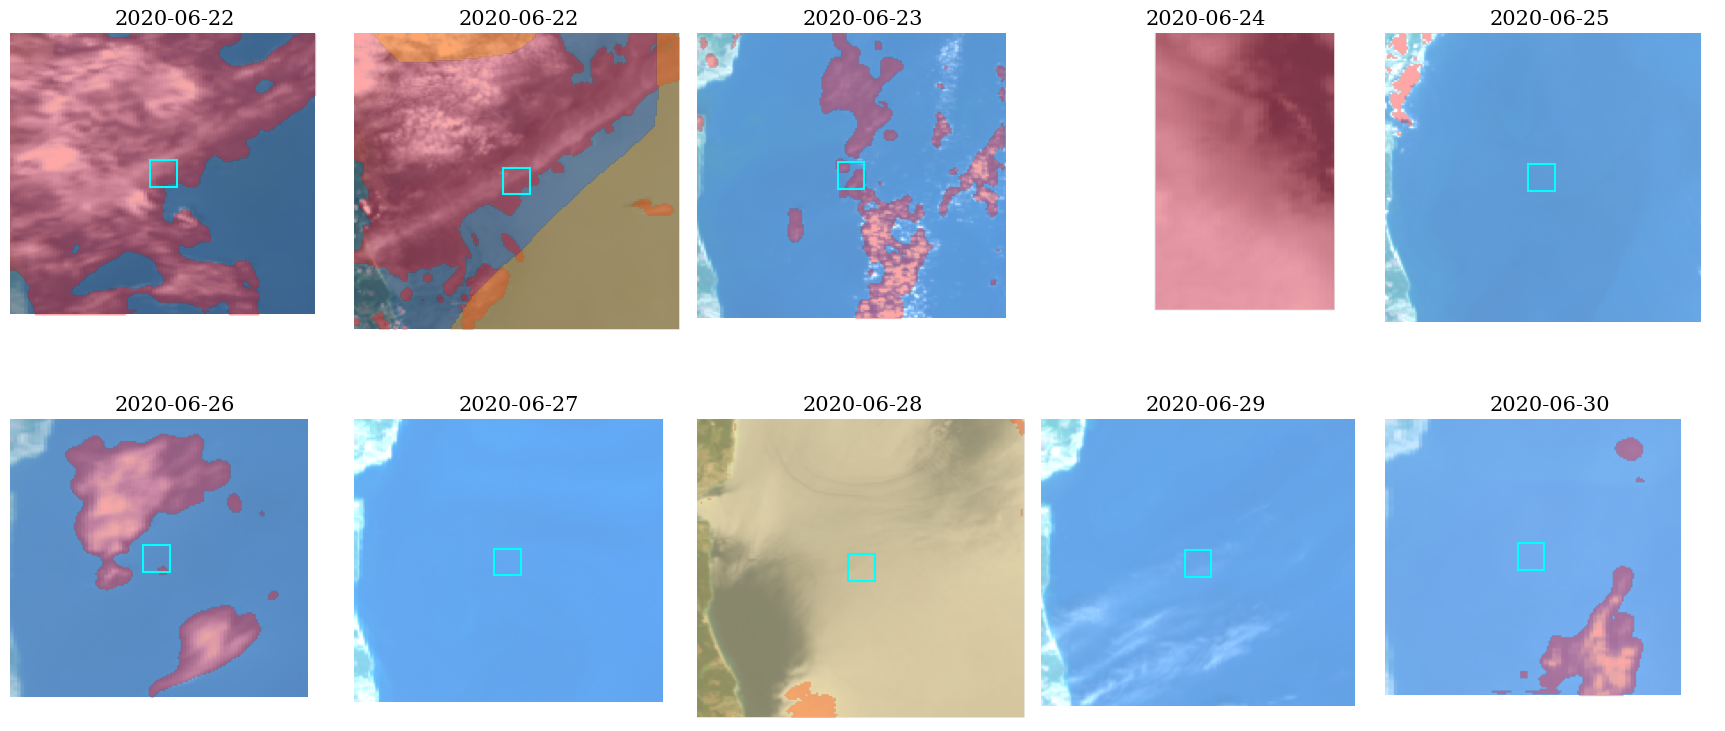

In [6]:
file = olci_files[3]
dc = xr.open_dataset(file).isel(time=slice(175, 185))
scenes = dc[['radiance', 'flags']].sel(wl=[665, 560, 490], method='nearest').load()

fig, axs = plt.subplots(2, 5, figsize=(22, 9.5))
fig.subplots_adjust(wspace=0.04, hspace=0.12)
cloud_cmap = mpl.colors.ListedColormap([(0, 0, 0, 0), 'red'])
glint_cmap = mpl.colors.ListedColormap([(0, 0, 0, 0), 'orange'])
for ax, (time, scene) in zip(axs.ravel(), scenes.groupby('time')):
    scene = scene.squeeze()
    rgb = (scene.radiance / scene.radiance.quantile(0.98)).clip(0, 1) ** 0.6
    ax.imshow(rgb.transpose('y', 'x', 'wl').values)
    ax.imshow((scene.flags & flag_mask(cloud_flags)) != 0, cmap=cloud_cmap, alpha=0.35, vmin=0, vmax=1)
    ax.imshow((scene.flags & flag_mask(glint_flags)) != 0, cmap=glint_cmap, alpha=0.35, vmin=0, vmax=1)
    station = olci.sel(time=time) if time in olci.time else None
    if station is not None:
        iy, ix = int(station.iy), int(station.ix)
        ax.add_patch(Rectangle((ix - half_neighbourhood - 0.5, iy - half_neighbourhood - 0.5),
                               2 * half_neighbourhood + 1, 2 * half_neighbourhood + 1,
                               fill=False, ec='cyan', lw=1.5))
    ax.set_title(pd.to_datetime(time).strftime('%Y-%m-%d'), fontsize=15)
    ax.set_axis_off()
plt.show()

## Screening of the scenes

The criteria are applied one after the other; the table gives the number of scenes left after each
of them.

In [7]:
box = olci.isel(dy=center, dx=center)

box_valid = ((box.flags & flag_mask(bad_flags)) == 0).all(['dy', 'dx'])
cloud_fraction = ((olci.flags & flag_mask(cloud_flags)) != 0).mean(['dy', 'dx'])
vza = box.OZA.mean(['dy', 'dx'])
sza = box.SZA.mean(['dy', 'dx'])
cv = (box.radiance.std(['dy', 'dx']) / box.radiance.mean(['dy', 'dx'])).sel(wl=cv_wl, drop=True)

criteria = {
    'box of 3x3 pixels without flag': box_valid,
    f'cloud fraction < {max_cloud_fraction:.0%}': cloud_fraction < max_cloud_fraction,
    f'VZA <= {max_vza} deg and SZA < {max_sza} deg': (vza <= max_vza) & (sza < max_sza),
    f'CV({cv_wl} nm) < {max_cv:.0%}': cv < max_cv,
}
valid = xr.ones_like(box_valid, dtype=bool)
counts = {'all the scenes': int(valid.sum())}
for name, criterion in criteria.items():
    valid = valid & criterion
    counts[name] = int(valid.sum())
pd.Series(counts, name='number of scenes').to_frame()

,number of scenes
all the scenes,2736
box of 3x3 pixels without flag,1128
cloud fraction < 5%,1038
VZA <= 40 deg and SZA < 70 deg,762
CV(865 nm) < 5%,639


For the valid scenes, the satellite radiance is summarized by the median and the spread of the
$3\times3$ pixels, with the mean geometry of the box.

The relative azimuth angle $\phi$ follows the radiative transfer convention of the RadCalNet-OC
look-up tables: $\phi = 0$ when the viewing direction points towards the Sun (specular reflection,
sunglint geometry) and $\phi = 180°$ for the backscattering geometry. With $\varphi_s$ the solar azimuth
angle and $\varphi_v$ the observation azimuth angle of the OLCI product (azimuth of the satellite seen
from the pixel), $\phi = |180° - (\varphi_s - \varphi_v) \bmod 360°|$.

In [8]:
box = box.sel(time=valid)
dims = ['dy', 'dx']
satellite = xr.Dataset({
    'L_median': box.radiance.median(dims),
    'L_q25': box.radiance.quantile(0.25, dims).drop_vars('quantile'),
    'L_q75': box.radiance.quantile(0.75, dims).drop_vars('quantile'),
    'L_min': box.radiance.min(dims),
    'L_max': box.radiance.max(dims),
    'L_std': box.radiance.std(dims),
    'sza': box.SZA.mean(dims),
    'vza': box.OZA.mean(dims),
    'azi': np.abs(180 - (box.SAA - box.OAA) % 360).mean(dims),
    'central_wl': box.central_wl,
    'fwhm': box.FWHM_mean,
    'platform': box.platform,
})
satellite

<xarray.Dataset> Size: 565kB
Dimensions:     (wl: 21, time: 639)
Coordinates:
  * wl          (wl) int64 168B 400 412 443 491 511 560 ... 865 884 899 939 1016
  * time        (time) datetime64[ns] 5kB 2017-01-12T08:34:27.692295012 ... 2...
Data variables:
    L_median    (time, wl) float32 54kB 42.15 48.23 44.15 ... 1.801 0.8204 1.562
    L_q25       (time, wl) float64 107kB 41.98 48.17 44.07 ... 0.8153 1.493
    L_q75       (time, wl) float64 107kB 42.17 48.25 44.26 ... 0.8255 1.614
    L_min       (time, wl) float32 54kB 41.83 48.07 43.99 ... 1.707 0.7847 1.356
    L_max       (time, wl) float32 54kB 42.3 48.31 44.28 ... 1.928 0.8713 1.79
    L_std       (time, wl) float32 54kB 0.1387 0.06971 0.1033 ... 0.02603 0.127
    sza         (time) float64 5kB 68.72 66.57 63.74 59.19 ... 59.59 65.44 68.54
    vza         (time) float64 5kB 8.61 34.47 2.734 19.99 ... 8.972 14.62 17.34
    azi         (time) float64 5kB 129.0 133.4 132.1 47.71 ... 55.98 57.06 53.96
    central_wl  (time, wl) float32 54kB 400.5 412.0 443.1 ... 938.8 1.016e+03
    fwhm        (time, wl) float32 54kB 14.0 9.839 9.956 ... 9.955 19.85 27.13
    platform    (time) <U3 8kB 'S3A' 'S3A' 'S3A' 'S3A' ... 'S3A' 'S3A' 'S3B'

## Simulated radiance in the OLCI bands

The RadCalNet-OC simulations are read lazily with dask. For each valid scene:

- the simulations within $\pm 1$ h of the overpass are selected;
- $R_{toa}$ is interpolated at the viewing zenith and relative azimuth angles of the scene and converted
  into radiance;
- the spectra are integrated over the spectral responses of the OLCI bands, from the central wavelengths
  and widths characterised for the platform (detector average); the convolution of
  {py:meth}`Spectral.convolve2 <radcalnet_oc.lut.Spectral.convolve2>` works directly on the dask arrays;
- the median, quartiles and number of the simulations are kept.

In [9]:
radcalnet = xr.open_mfdataset(radcalnet_files, chunks={'time': 1}, data_vars='minimal', coords='minimal',
                              compat='override')[['Rtoa', 'E0']]
# spectral range of the OLCI bands
radcalnet = radcalnet.sel(wl=slice(370, 1060))
simulation_times = radcalnet.time.values
print(f'{radcalnet.sizes["time"]} simulations from {str(simulation_times[0])[:10]} to {str(simulation_times[-1])[:10]}')

7586 simulations from 2017-01-02 to 2023-01-01


In [10]:
matchups = []
for time in satellite.time.values:
    window = (simulation_times >= time - delta_time) & (simulation_times <= time + delta_time)
    if not window.any():
        continue
    scene = satellite.sel(time=time)
    simu = radcalnet.isel(time=np.flatnonzero(window))
    Ltoa = (simu.Rtoa.interp(vza=float(scene.vza), azi=float(scene.azi)) * simu.E0 / np.pi).rename('Ltoa')

    spectral = radoc.Spectral(central_wl=scene.central_wl.values.astype(float),
                              fwhm=scene.fwhm.values.astype(float))
    Lb = spectral.convolve2(Ltoa).Ltoa.reset_coords(drop=True).assign_coords(wl=satellite.wl.values).compute()

    matchups.append(xr.Dataset({
        'Lsim_median': Lb.median('time'),
        'Lsim_q25': Lb.quantile(0.25, 'time').drop_vars('quantile'),
        'Lsim_q75': Lb.quantile(0.75, 'time').drop_vars('quantile'),
        'Lsim_std': Lb.std('time'),
        'Lsim_count': Lb.sizes['time'],
        'time_simulation': simu.time.mean(),
    }).expand_dims(time=[time]))

matchup = xr.merge([satellite, xr.concat(matchups, dim='time')], join='inner')
matchup['ratio'] = matchup.L_median / matchup.Lsim_median
print(f'{matchup.sizes["time"]} matchups:',
      ', '.join(f'{p} {n}' for p, n in zip(*np.unique(matchup.platform.values, return_counts=True))))

375 matchups: S3A 200, S3B 175


## Comparison

### Example of matchup

Simulated spectrum at full resolution (median of the simulations of the time window), simulated
radiance in the OLCI bands and radiance measured by OLCI (median, range of the $3\times3$ pixels).

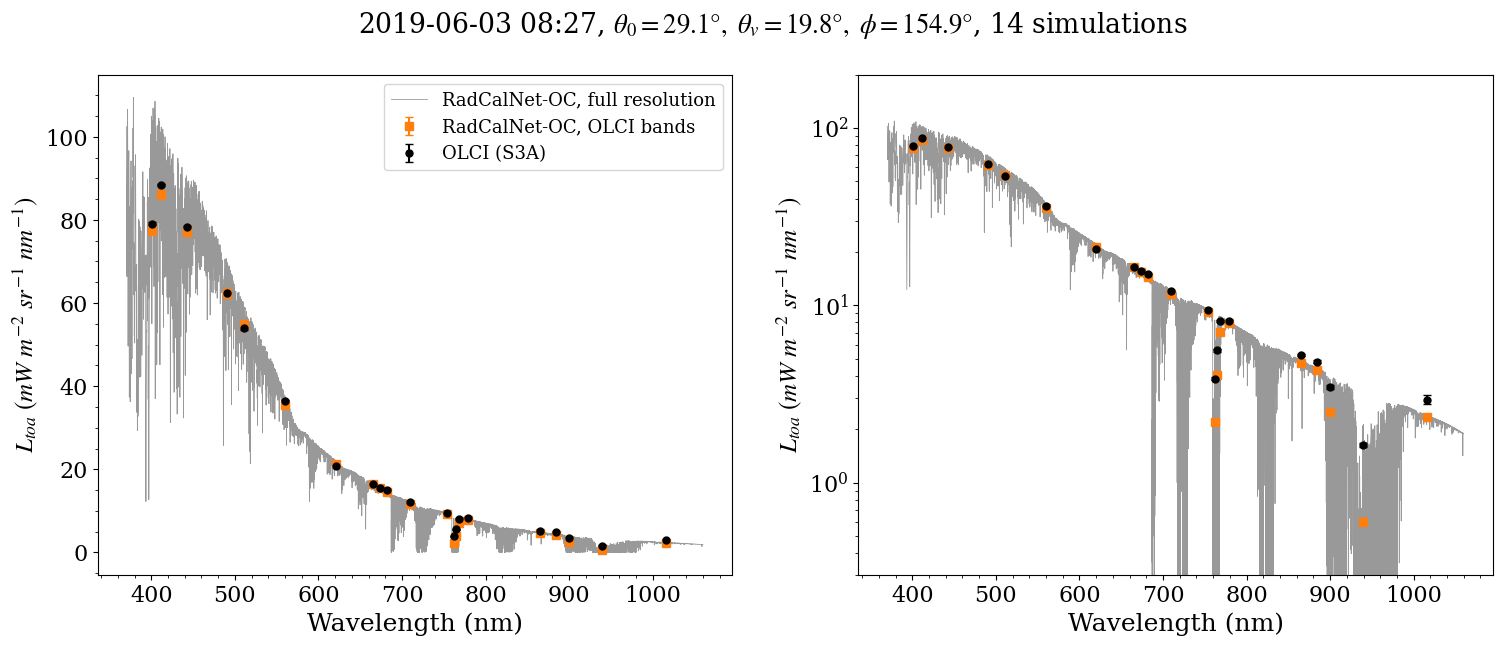

In [11]:
example = matchup.isel(time=int(np.argmax(matchup.Lsim_count.values)))
time = example.time.values
window = (simulation_times >= time - delta_time) & (simulation_times <= time + delta_time)
simu = radcalnet.isel(time=np.flatnonzero(window))
Ltoa_full = (simu.Rtoa.interp(vza=float(example.vza), azi=float(example.azi)) * simu.E0 / np.pi).median('time')

wl = example.central_wl
fig, axs = plt.subplots(1, 2, figsize=(18, 6.5))
for ax in axs:
    Ltoa_full.plot(ax=ax, color='grey', lw=0.6, alpha=0.8, label='RadCalNet-OC, full resolution')
    ax.errorbar(wl, example.Lsim_median, yerr=[example.Lsim_median - example.Lsim_q25,
                                               example.Lsim_q75 - example.Lsim_median],
                fmt='s', color='tab:orange', ms=6, capsize=3, label='RadCalNet-OC, OLCI bands')
    ax.errorbar(wl, example.L_median, yerr=[example.L_median - example.L_min, example.L_max - example.L_median],
                fmt='o', color='k', ms=5, capsize=3, label=f'OLCI ({str(example.platform.values)})')
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel(r'$L_{toa}\ (mW\ m^{-2}\ sr^{-1}\ nm^{-1})$')
    ax.set_title('')
    ax.minorticks_on()
axs[1].semilogy()
axs[1].set_ylim(0.3, 200)
axs[0].legend(fontsize=13)
fig.suptitle(pd.to_datetime(time).strftime('%Y-%m-%d %H:%M') +
             r', $\theta_0=%.1f°,\ \theta_v=%.1f°,\ \phi=%.1f°$, %i simulations'
             % (example.sza, example.vza, example.azi, example.Lsim_count))
plt.show()

### Gaseous absorption bands

The bands in the oxygen A-band (761, 764 and 767 nm) and in the water vapour bands (900 and 939 nm) sample narrow
absorption features: the band radiance is very sensitive to the shape of the spectral response, which is
only modelled here, and to the gas columns. These bands are shown in grey and are not used in the
statistics.

In [12]:
absorption_bands = [762, 765, 768, 899, 939]
bands = [b for b in matchup.wl.values if b not in absorption_bands]
platforms = {'S3A': 'tab:blue', 'S3B': 'tab:red'}

### Time series

Ratio of the measured to the simulated radiance; the error bars combine the interquartile ranges of the
satellite pixels and of the simulations.

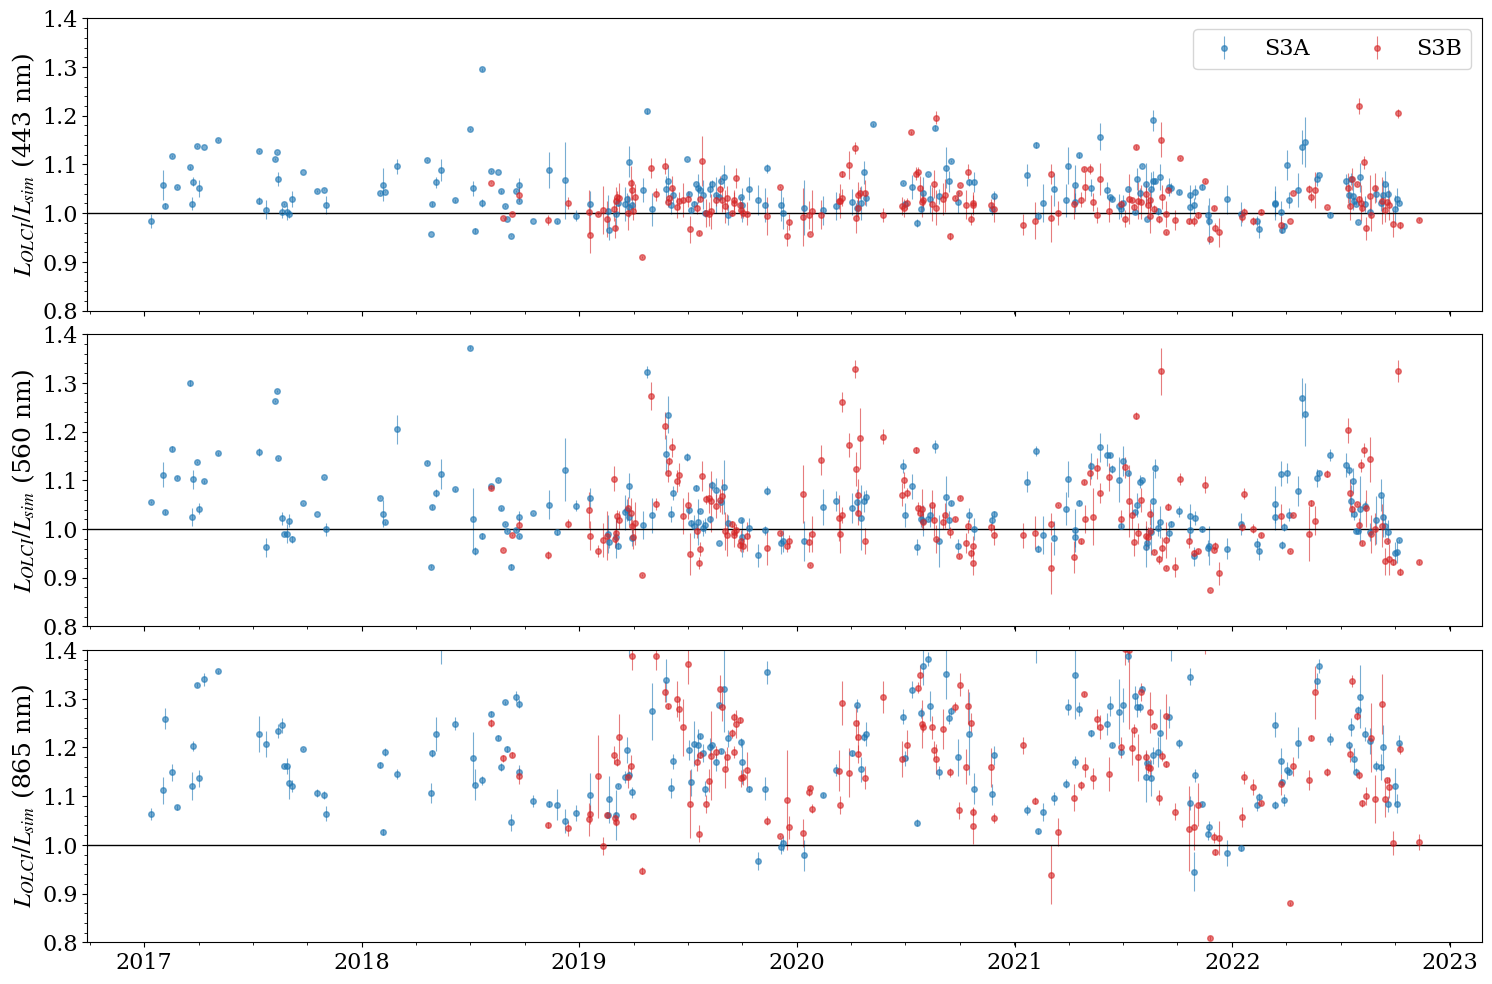

In [13]:
fig, axs = plt.subplots(3, 1, figsize=(18, 12), sharex=True)
fig.subplots_adjust(hspace=0.08)
for ax, band in zip(axs, [443, 560, 865]):
    mb = matchup.sel(wl=band)
    for platform, color in platforms.items():
        mp = mb.where(mb.platform == platform, drop=True)
        rel_err = np.sqrt(((mp.L_q75 - mp.L_q25) / mp.L_median) ** 2 +
                          ((mp.Lsim_q75 - mp.Lsim_q25) / mp.Lsim_median) ** 2) / 2
        ax.errorbar(mp.time.values, mp.ratio, yerr=rel_err * mp.ratio, fmt='o', ms=4, color=color,
                    ecolor=color, elinewidth=0.8, alpha=0.6, label=platform)
    ax.axhline(1, color='k', lw=1)
    ax.set_ylabel(r'$L_{OLCI}/L_{sim}$' + f' ({band} nm)')
    ax.set_ylim(0.8, 1.4)
    ax.minorticks_on()
axs[0].legend(ncol=2)
plt.show()

### Scatter plots

For each band: regression line, correlation coefficient $r$, root mean square difference (RMSD), mean bias,
median symmetric accuracy $\epsilon$ and symmetric signed percentage bias $\beta$
(Morley et al., 2018), with

$$
\epsilon = 100\,\left(10^{\,\mathrm{median}\left|\log_{10}(y/x)\right|} - 1\right), \qquad
\beta = 100\ \mathrm{sign}(Z)\left(10^{|Z|} - 1\right),\quad Z = \mathrm{median}\left(\log_{10}(y/x)\right).
$$

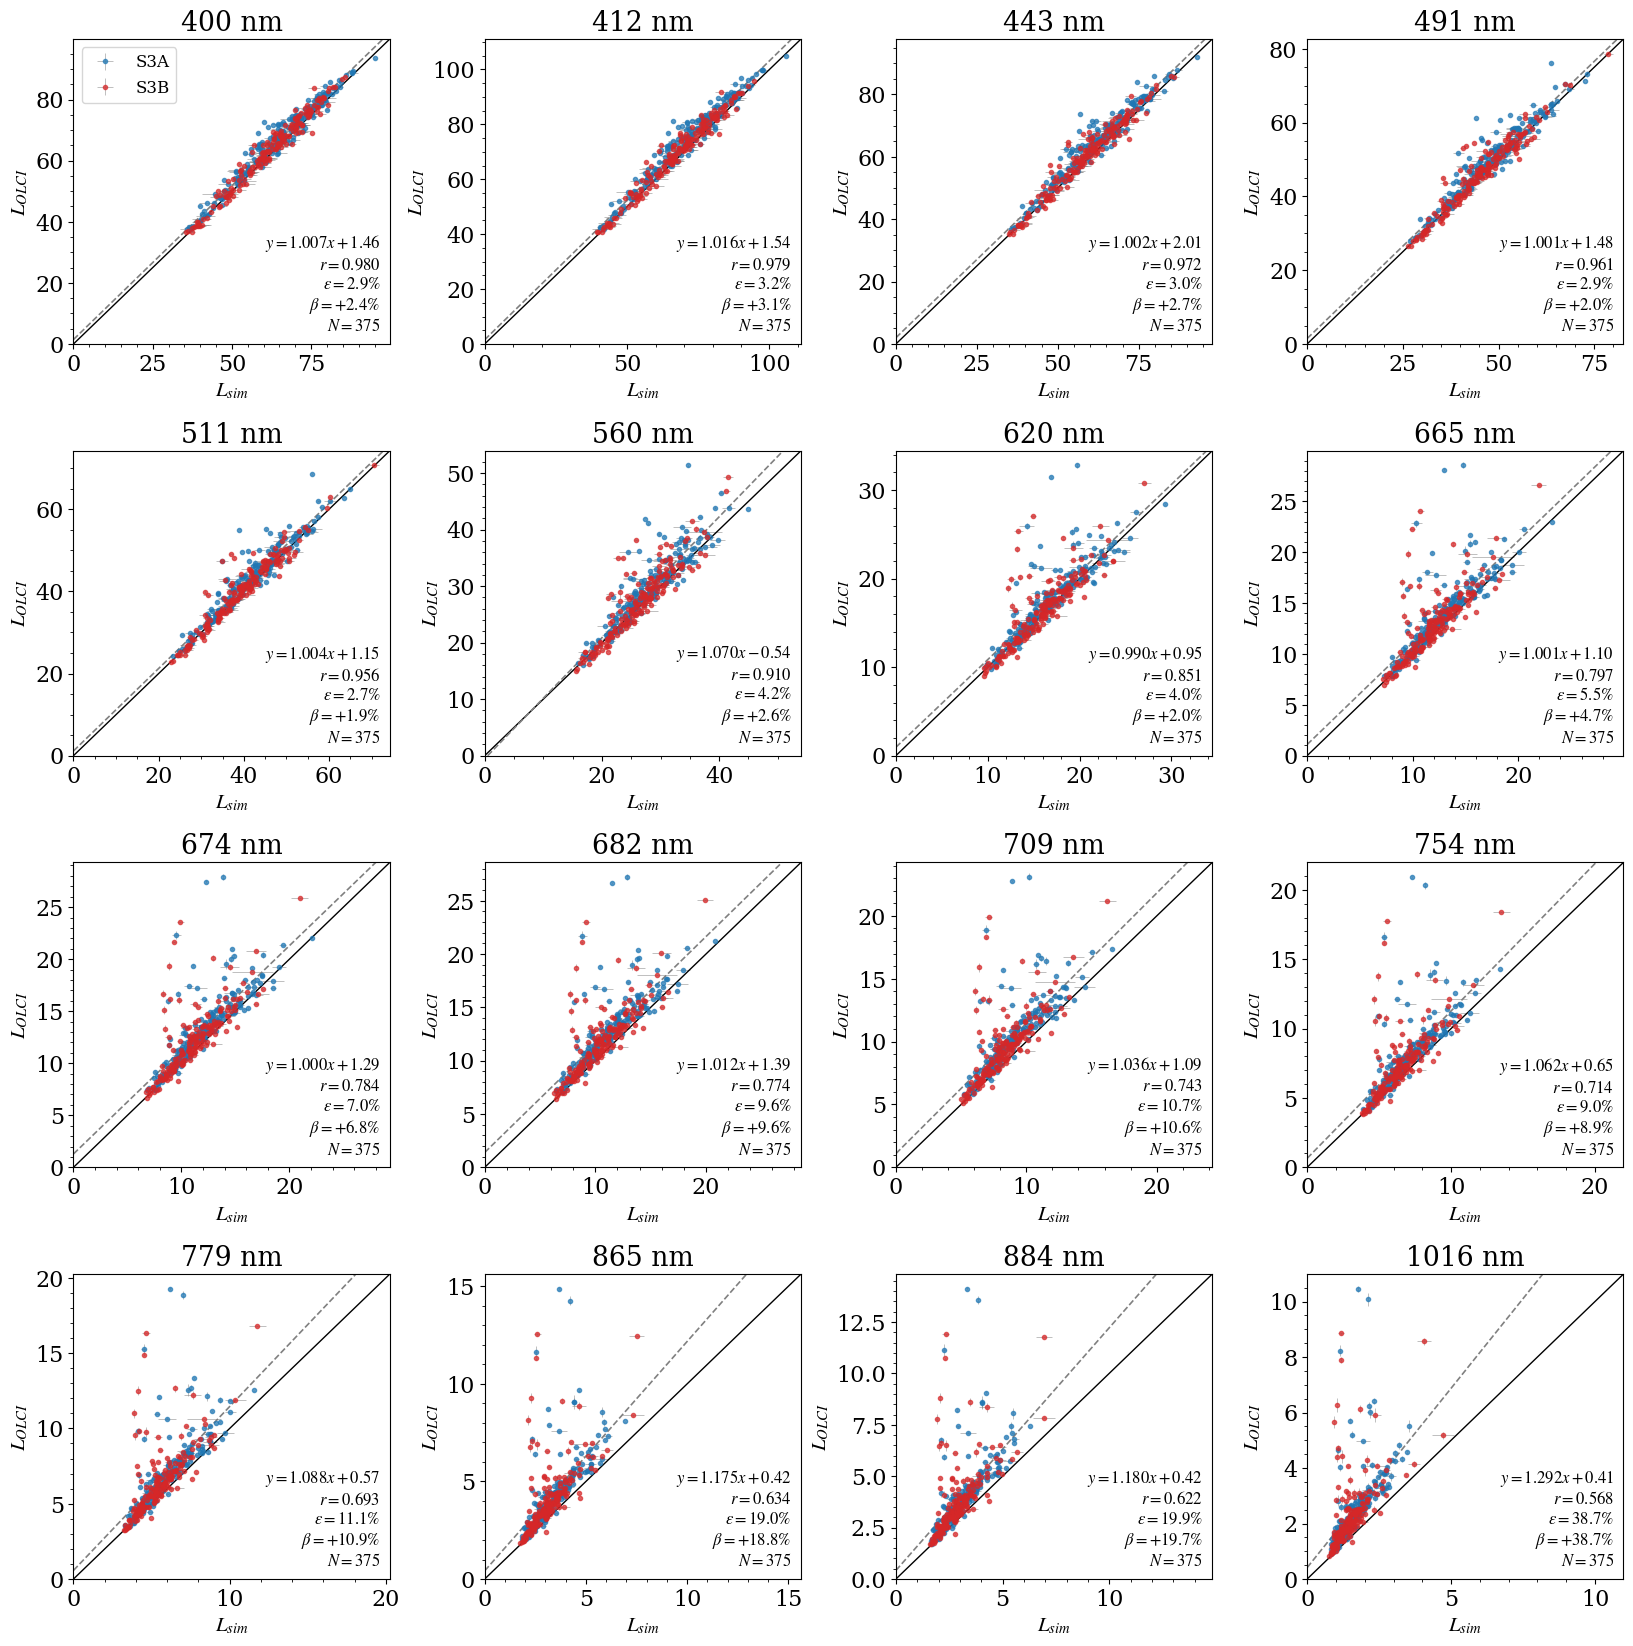

In [14]:
def matchup_stats(x, y):
    regression = scipy.stats.linregress(x, y)
    log_ratio = np.log10(y / x)
    z = np.median(log_ratio)
    return {'N': len(x),
            'slope': regression.slope,
            'intercept': regression.intercept,
            'r': regression.rvalue,
            'RMSD': np.sqrt(np.mean((y - x) ** 2)),
            'bias': np.mean(y - x),
            'epsilon (%)': 100 * (10 ** np.median(np.abs(log_ratio)) - 1),
            'beta (%)': 100 * np.sign(z) * (10 ** np.abs(z) - 1)}


ncols = 4
nrows = int(np.ceil(len(bands) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
fig.subplots_adjust(hspace=0.35, wspace=0.3)
for ax, band in zip(axs.ravel(), bands):
    mb = matchup.sel(wl=band)
    for platform, color in platforms.items():
        mp = mb.where(mb.platform == platform, drop=True)
        ax.errorbar(mp.Lsim_median, mp.L_median, xerr=mp.Lsim_std, yerr=mp.L_std, fmt='o', ms=3,
                    color=color, ecolor='grey', elinewidth=0.5, alpha=0.7, label=platform)
    x, y = mb.Lsim_median.values, mb.L_median.values
    stats = matchup_stats(x, y)
    lim = [0, 1.05 * max(x.max(), y.max())]
    ax.plot(lim, lim, 'k-', lw=1)
    ax.axline((0, stats['intercept']), slope=stats['slope'], ls='--', lw=1.2, color='grey')
    ax.text(0.97, 0.03, '$y = %.3f x %+.2f$\n$r = %.3f$\n$\\epsilon = %.1f\\%%$\n$\\beta = %+.1f\\%%$\n$N = %i$'
            % (stats['slope'], stats['intercept'], stats['r'], stats['epsilon (%)'], stats['beta (%)'],
               stats['N']), transform=ax.transAxes, ha='right', va='bottom', fontsize=12)
    ax.set(xlim=lim, ylim=lim, title=f'{band} nm')
    ax.set_xlabel(r'$L_{sim}$', fontsize=15)
    ax.set_ylabel(r'$L_{OLCI}$', fontsize=15)
    ax.minorticks_on()
for ax in axs.ravel()[len(bands):]:
    ax.set_axis_off()
axs[0, 0].legend(fontsize=12, loc='upper left')
plt.show()

In [15]:
pd.DataFrame({band: matchup_stats(matchup.Lsim_median.sel(wl=band).values, matchup.L_median.sel(wl=band).values)
              for band in bands}).T.round(3)

,N,slope,intercept,r,RMSD,bias,epsilon (%),beta (%)
400,375.0,1.007,1.463,0.980,3.097,1.904,2.932,2.383
412,375.0,1.016,1.542,0.979,3.857,2.656,3.239,3.090
443,375.0,1.002,2.006,0.972,3.496,2.120,3.033,2.669
491,375.0,1.001,1.480,0.961,3.098,1.539,2.906,2.035
511,375.0,1.004,1.145,0.956,2.866,1.325,2.734,1.913
560,375.0,1.070,-0.538,0.910,3.038,1.368,4.221,2.569
620,375.0,0.990,0.953,0.851,2.273,0.782,4.017,1.953
665,375.0,1.001,1.095,0.797,2.389,1.106,5.499,4.680
674,375.0,1.000,1.289,0.784,2.479,1.293,7.006,6.821
682,375.0,1.012,1.394,0.774,2.596,1.524,9.645,9.550


### Ratio per band

Median and interquartile range of the ratio of the measured to the simulated radiance, for each platform.
A ratio above 1 means that OLCI measures a higher radiance than simulated.

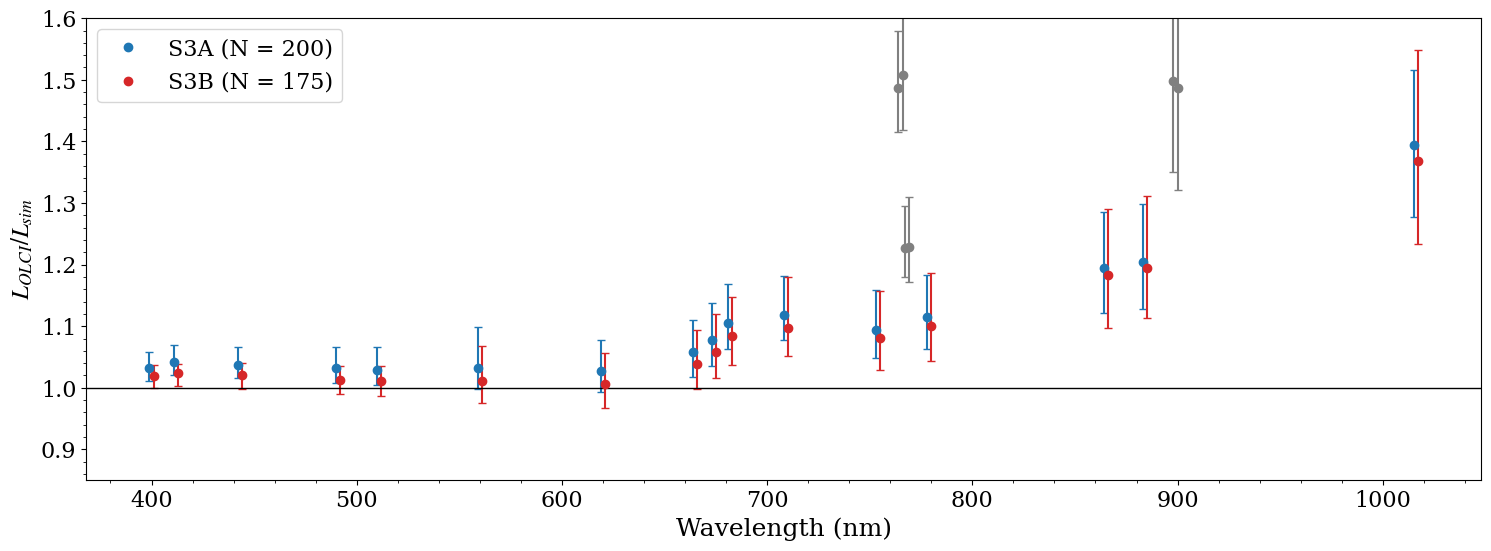

wl,400,412,443,491,511,560,620,665,674,682,709,754,779,865,884,1016
S3A median,1.032,1.042,1.038,1.032,1.029,1.032,1.027,1.058,1.077,1.104,1.119,1.094,1.115,1.195,1.204,1.393
S3A IQR,0.046,0.049,0.049,0.058,0.061,0.100,0.084,0.093,0.103,0.106,0.104,0.110,0.120,0.164,0.170,0.239
S3B median,1.019,1.024,1.020,1.013,1.011,1.011,1.006,1.039,1.057,1.084,1.097,1.080,1.100,1.182,1.195,1.369
S3B IQR,0.038,0.036,0.042,0.046,0.049,0.092,0.089,0.095,0.103,0.111,0.128,0.129,0.143,0.193,0.199,0.315


In [16]:
fig, ax = plt.subplots(figsize=(18, 6))
summary = {}
for ii, (platform, color) in enumerate(platforms.items()):
    ratio = matchup.ratio.where(matchup.platform == platform, drop=True)
    median = ratio.median('time')
    q25, q75 = ratio.quantile(0.25, 'time'), ratio.quantile(0.75, 'time')
    shift = (ii - 0.5) * 2
    for band in matchup.wl.values:
        c = 'grey' if band in absorption_bands else color
        ax.errorbar(band + shift, median.sel(wl=band), yerr=[[median.sel(wl=band) - q25.sel(wl=band)],
                                                              [q75.sel(wl=band) - median.sel(wl=band)]],
                    fmt='o', color=c, capsize=3, ms=6)
    ax.plot([], [], 'o', color=color, label=f'{platform} (N = {ratio.sizes["time"]})')
    summary[platform + ' median'] = median.to_series()
    summary[platform + ' IQR'] = (q75 - q25).to_series()
ax.axhline(1, color='k', lw=1)
ax.set_ylim(0.85, 1.6)
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel(r'$L_{OLCI}/L_{sim}$')
ax.legend()
ax.minorticks_on()
plt.show()

pd.DataFrame(summary).loc[bands].round(3).T

## Saving the matchups

The matchup dataset (satellite statistics, simulation statistics, geometry and platform for each scene)
is saved in a NetCDF file.

In [17]:
os.makedirs(odir, exist_ok=True)
ofile = os.path.join(odir, f'{site}_olci_radcalnet-oc_matchup.nc')
matchup.attrs = {'site': site, 'latitude': site_lat, 'longitude': site_lon,
                 'description': 'OLCI Level-1B radiance (3x3 pixels) vs RadCalNet-OC simulations '
                                f'(+/- {delta_time.astype(int)} h); radiance in mW m-2 sr-1 nm-1',
                 'radcalnet_oc_version': radoc.__version__}
matchup.to_netcdf(ofile)
print(ofile)

/data/radcalnet/sentinel3/matchup/Galata_Platform_olci_radcalnet-oc_matchup.nc
